# IMDb Sentiment Analysis using DistilBERT + TensorFlow

Fine-tune a pretrained **DistilBERT** model for binary movie-review sentiment classification using **TensorFlow/Keras through KerasHub**.

This notebook keeps the workflow straightforward:
1. Load IMDb reviews
2. Prepare a manageable train/validation/test sample
3. Load pretrained DistilBERT and its tokenizer/preprocessor
4. Fine-tune the classifier
5. Evaluate with standard classification metrics
6. Inspect misclassified reviews and high-confidence errors

**Framework:** TensorFlow + KerasHub  
**Pretrained model:** `distil_bert_base_en_uncased`  
**Dataset:** IMDb movie reviews  
**Task:** Positive / negative sentiment classification

> This is a TensorFlow implementation. It does not use PyTorch or Hugging Face Trainer.

## 1. Install dependencies

Run once in a fresh environment. A GPU runtime (Google Colab T4, if available) is strongly recommended for fine-tuning DistilBERT.

In [1]:

%pip install -q --upgrade tensorflow keras-hub tensorflow-datasets scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.33.0 which is incompatible.


## 2. Imports and configuration

We use a short sequence length and a subset of the dataset to keep the experiment manageable. The held-out test sample is not used for training or validation.

In [ ]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import keras
import keras_hub

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 2e-5
THRESHOLD = 0.5

TRAIN_SAMPLES = 8000
TEST_SAMPLES = 5000

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasHub:", keras_hub.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


TensorFlow: 2.21.0
Keras: 3.15.1
KerasHub: 0.33.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load the IMDb dataset

The IMDb dataset is loaded with Keras (`keras.datasets.imdb`). It downloads automatically on the first run; no manual CSV download is required.

- 25,000 labelled training reviews
- 25,000 labelled test reviews
- Label `0` = negative, `1` = positive

Keras stores each review as a list of word indices, so the cell below converts them back to text for the DistilBERT tokenizer. The rebuilt text is lowercase and has no punctuation.

We use a stratified subset for a quicker first experiment. Increase `TRAIN_SAMPLES` and `TEST_SAMPLES` later if you have enough GPU time.

In [3]:
!pip install importlib_resources

In [4]:
import numpy as np
import keras

print("Loading IMDb dataset via Keras...")
# Load pre-tokenized indices from Keras
(train_data, train_label_all), (test_data, test_label_all) = keras.datasets.imdb.load_data()

# Convert indices back to text reviews so your downstream tokenizer (DistilBERT) can process them
word_index = keras.datasets.imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(text_ids):
    # Note that the indices are offset by 3 because 0, 1, and 2 are reserved
    # for "padding", "start of sequence", and "unknown".
    return " ".join([reverse_word_index.get(i - 3, "?") for i in text_ids])

print("Decoding train reviews...")
train_text_all = np.array([decode_review(seq).encode('utf-8') for seq in train_data], dtype=object)

print("Decoding test reviews...")
test_text_all = np.array([decode_review(seq).encode('utf-8') for seq in test_data], dtype=object)

print("Full training set:", len(train_text_all))
print("Full test set:", len(test_text_all))

Loading IMDb dataset via Keras...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Decoding train reviews...
Decoding test reviews...
Full training set: 25000
Full test set: 25000


## 4. Create train, validation and test samples

We create a stratified validation split from the training portion. The official test split remains separate.

In [5]:
# Stratified subset from the official training split
x_train, _, y_train, _ = train_test_split(
    train_text_all,
    train_label_all,
    train_size=TRAIN_SAMPLES,
    random_state=SEED,
    stratify=train_label_all,
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train,
)

# Stratified sample from the official test split
x_test, _, y_test, _ = train_test_split(
    test_text_all,
    test_label_all,
    train_size=TEST_SAMPLES,
    random_state=SEED,
    stratify=test_label_all,
)

print("Train:", len(x_train))
print("Validation:", len(x_val))
print("Test:", len(x_test))
print("Example review:", x_train[0].decode("utf-8")[:500])
print("Example label:", "Positive" if y_train[0] == 1 else "Negative")

Train: 6400
Validation: 1600
Test: 5000
Example review: ? zabriskie point 1970 this was especially interesting to me on a personal level since it takes place under identical circumstances with identical peers in my own life  the counter culture movement of the late 60's early 70's on and off campus we follow two unrelated young people in separate stories who are slowly woven together one is a young man in los angeles tired of all the endless pseudo revolutionary jabber in the classrooms and lunchrooms of his campus and the other a young woman drivin
Example label: Positive


## 5. Load pretrained DistilBERT

KerasHub provides a pretrained DistilBERT text-classification model and its text preprocessor. The preprocessor handles tokenization, special tokens, truncation and padding.

We attach a two-class classification head and fine-tune the pretrained model on IMDb.

In [6]:
PRESET = "distil_bert_base_en_uncased"

preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(
    PRESET,
    sequence_length=MAX_LENGTH,
)

model = keras_hub.models.DistilBertTextClassifier.from_preset(
    PRESET,
    num_classes=2,
    preprocessor=preprocessor,
)

model.summary()

Preprocessor: "distil_bert_text_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model

The model returns class logits, so we use sparse categorical cross-entropy with `from_logits=True`. A small learning rate is typical when fine-tuning a pretrained Transformer.

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

## 7. Fine-tune DistilBERT

We train for two epochs with early stopping. Fine-tuning a Transformer is computationally heavier than training a small LSTM, so use a GPU runtime when possible.

In [8]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True,
)

history = model.fit(
    x=x_train,
    y=y_train,
    validation_data=(x_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
400/400 ━━━━━━━━━━━━━━━━━━━━ 136s 238ms/step - accuracy: 0.8067 - loss: 0.4184 - val_accuracy: 0.8450 - val_loss: 0.3516
Epoch 2/2
400/400 ━━━━━━━━━━━━━━━━━━━━ 89s 223ms/step - accuracy: 0.9016 - loss: 0.2491 - val_accuracy: 0.8306 - val_loss: 0.3979


## 8. Plot training and validation curves

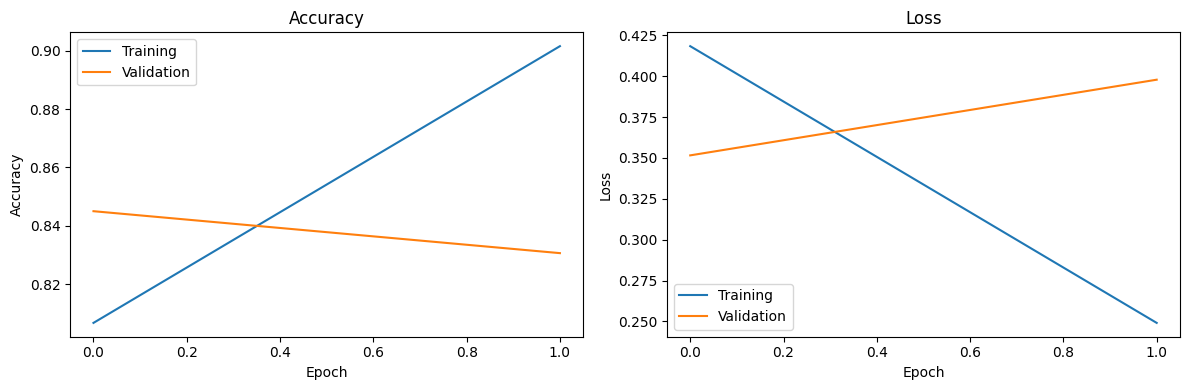

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Evaluate on the held-out test sample

DistilBERT returns two logits per review. We convert them to positive-class probabilities with softmax and apply a 0.5 decision threshold.

In [10]:
test_logits = model.predict(x_test, batch_size=BATCH_SIZE, verbose=1)
test_probabilities = tf.nn.softmax(test_logits, axis=1).numpy()[:, 1]
y_pred = (test_probabilities >= THRESHOLD).astype(int)

test_accuracy = accuracy_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, test_probabilities)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0,
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 63s 188ms/step
Test accuracy: 0.8572
Test ROC-AUC: 0.9430

              precision    recall  f1-score   support

    Negative     0.9185    0.7840    0.8459      2500
    Positive     0.8116    0.9304    0.8669      2500

    accuracy                         0.8572      5000
   macro avg     0.8650    0.8572    0.8564      5000
weighted avg     0.8650    0.8572    0.8564      5000



## 10. Confusion matrix

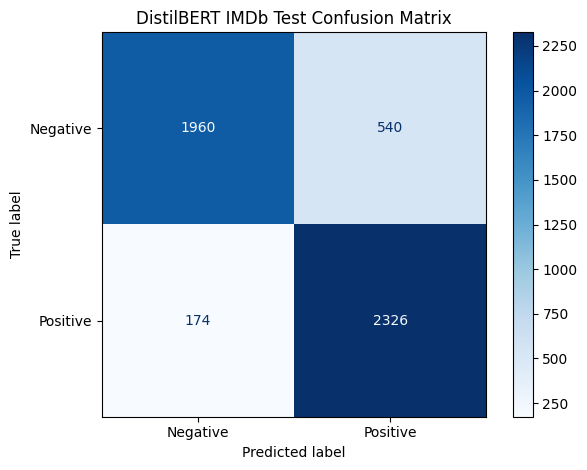

In [11]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT IMDb Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Error analysis

Inspect false positives and false negatives, then review high-confidence mistakes. This helps identify examples involving negation, sarcasm, mixed opinions or ambiguous wording.

In [13]:
from IPython.display import display as show_table

error_rows = []

for idx, (true_label, pred_label, prob) in enumerate(
    zip(y_test, y_pred, test_probabilities)
):
    if true_label != pred_label:
        confidence = max(float(prob), 1.0 - float(prob))
        error_rows.append({
            "true_label": "Positive" if true_label == 1 else "Negative",
            "predicted_label": "Positive" if pred_label == 1 else "Negative",
            "positive_probability": float(prob),
            "confidence": confidence,
            "review": x_test[idx].decode("utf-8"),
        })

errors_df = pd.DataFrame(error_rows)
errors_df.to_csv(OUTPUT_DIR / "misclassified_reviews.csv", index=False)

print("Test reviews:", len(y_test))
print("Misclassified reviews:", len(errors_df))

show_table(errors_df.head(10))

Test reviews: 5000
Misclassified reviews: 714


,true_label,predicted_label,positive_probability,confidence,review
0,Negative,Positive,0.653960,0.653960,? many people are standing in front of the hou...
1,Negative,Positive,0.554040,0.554040,? call me old fashioned but i like movies with...
2,Negative,Positive,0.685190,0.685190,? i really wanted to like this film especially...
3,Negative,Positive,0.906507,0.906507,? i found this robin williams vehicle mildly a...
4,Negative,Positive,0.898973,0.898973,? brainy cross dressing little boy finds succe...
5,Negative,Positive,0.870351,0.870351,? for me this movie is essentially like a feat...
6,Negative,Positive,0.558459,0.558459,? i wasn't expecting much from this film but w...
7,Negative,Positive,0.901507,0.901507,? hedy lamarr who may have been kept by more m...
8,Negative,Positive,0.764046,0.764046,? i know that full moon or any other film stud...
9,Positive,Negative,0.425089,0.574911,? i saw this a good while ago but i just cant ...


### 11.1 High-confidence incorrect predictions

These are examples where the model was confident but wrong. Inspect them manually rather than treating confidence as correctness.

In [15]:
if not errors_df.empty:
    high_confidence_errors = errors_df.nlargest(20, "confidence")
    high_confidence_errors.to_csv(
        OUTPUT_DIR / "high_confidence_errors.csv", index=False
    )
    show_table(high_confidence_errors[
        ["true_label", "predicted_label", "positive_probability", "confidence", "review"]
    ])
else:
    print("No misclassified reviews in this test sample.")

,true_label,predicted_label,positive_probability,confidence,review
556,Positive,Negative,0.024966,0.975034,? i just saw this for the first time in 10 or ...
230,Negative,Positive,0.974581,0.974581,? i really liked this quirky movie the charact...
395,Negative,Positive,0.972485,0.972485,? this has to be one of if not the greatest mo...
379,Negative,Positive,0.970699,0.970699,? my friend and i rented this one a few nights...
392,Negative,Positive,0.970119,0.970119,? this film has the language the style and the...
342,Negative,Positive,0.965898,0.965898,? i didn't hate this one i just couldn't adapt...
459,Positive,Negative,0.037270,0.962730,? i don't know how i would feel if i lived in ...
425,Negative,Positive,0.961751,0.961751,? as i write this in november 2005 i've become...
28,Negative,Positive,0.961457,0.961457,? this movie is very violent yet exciting with...
313,Negative,Positive,0.960887,0.960887,? the only reason there is a question mark in ...


## 12. Try custom movie reviews

The same DistilBERT model accepts raw review strings; its attached preprocessor tokenizes them automatically.

In [16]:
custom_reviews = [
    "This movie was wonderful. The acting was excellent and the story was moving.",
    "The story was boring and the acting was terrible. I would not recommend it.",
]

custom_logits = model.predict(custom_reviews, verbose=0)
custom_probabilities = tf.nn.softmax(custom_logits, axis=1).numpy()

for review, probs in zip(custom_reviews, custom_probabilities):
    predicted_label = int(np.argmax(probs))
    sentiment = "Positive" if predicted_label == 1 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probs[1]:.3f}")
    print("-" * 70)

Review: This movie was wonderful. The acting was excellent and the story was moving.
Predicted sentiment: Positive
Positive probability: 0.972
----------------------------------------------------------------------
Review: The story was boring and the acting was terrible. I would not recommend it.
Predicted sentiment: Negative
Positive probability: 0.031
----------------------------------------------------------------------


## 13. Save model and evaluation results

In [17]:
model.save(OUTPUT_DIR / "distilbert_imdb.keras")

metrics = {
    "model": PRESET,
    "train_samples": int(len(x_train)),
    "validation_samples": int(len(x_val)),
    "test_samples": int(len(x_test)),
    "epochs_trained": int(len(history.history["loss"])),
    "test_accuracy": float(test_accuracy),
    "test_roc_auc": float(test_roc_auc),
    "threshold": THRESHOLD,
}

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Saved model and metrics in:", OUTPUT_DIR.resolve())
print(metrics)

Saved model and metrics in: /content/outputs
{'model': 'distil_bert_base_en_uncased', 'train_samples': 6400, 'validation_samples': 1600, 'test_samples': 5000, 'epochs_trained': 2, 'test_accuracy': 0.8572, 'test_roc_auc': 0.94299424, 'threshold': 0.5}


## 14. Conclusion and limitations

This project demonstrates transfer learning for NLP: a pretrained DistilBERT encoder is fine-tuned for binary sentiment classification, then evaluated with class-wise metrics and error analysis.

**Limitations**
- The first experiment uses a subset of IMDb to keep fine-tuning manageable. The sample sizes are recorded in `metrics.json`.
- Reviews are cut to 128 tokens and rebuilt from word indices (lowercase, no punctuation).
- Results are dependent on the selected sample, training duration and hardware.
- Custom-review examples are illustrative, not a substitute for a broader external test set.
- No API, web app, Docker or production deployment is included.